In [1]:
import sys
import os

# Add project root to path
sys.path.insert(0, os.path.abspath(".."))

# Now the import should work
from src.data import load_train_val_test

In [2]:
from datasets import load_dataset
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

In [6]:
train_df, val_df, test_df, label_list = load_train_val_test()

In [7]:
train_df.head()

,text,label
725,"GP/ILS FREQ 333,2 MHZ U/S",3
3366,SID RNAV PULUR 1A RWY 29 NOT AVBL,6
3853,IN VIEW OF MONSOON SEASON. HEAVY BIRD ACTIVITY...,12
656,ILS RWY 25R LOC/DME U/S,3
1119,"SAN DIEGO, CA LASER LGT DEMONSTRATION\nWI AN A...",0


In [8]:
print(label_list)

['Airspaces', 'Communication_and_Radar', 'GPS', 'Landing_Navaids', 'Obstacles', 'Parking', 'Procedure', 'Runway', 'Services_and_Facilities', 'Signs_and_Lights', 'Taxiway', 'Terminal_or_Enroute_Navaids', 'Wildlife']


# Class distribution across all three splits.

In [9]:
train_counts = train_df['label'].value_counts(normalize=True).sort_index()
val_counts = val_df['label'].value_counts(normalize=True).sort_index()
test_counts = test_df['label'].value_counts(normalize=True).sort_index()

class_distribution = pd.DataFrame({
    'Train': train_counts,
    'Validation': val_counts,
    'Test': test_counts
})

class_distribution.index = [label_list[i] for i in class_distribution.index]
print('Class Distribution Across Splits:')
class_distribution

Class Distribution Across Splits:


,Train,Validation,Test
Airspaces,0.124816,0.125000,0.124735
Communication_and_Radar,0.052523,0.053066,0.052818
GPS,0.078489,0.077830,0.078283
Landing_Navaids,0.183830,0.183962,0.183683
Obstacles,0.079965,0.080189,0.079934
Parking,0.047507,0.047170,0.047394
Procedure,0.051048,0.050708,0.051167
Runway,0.097964,0.097877,0.098090
Services_and_Facilities,0.055474,0.055425,0.055411
Signs_and_Lights,0.048097,0.048349,0.048102


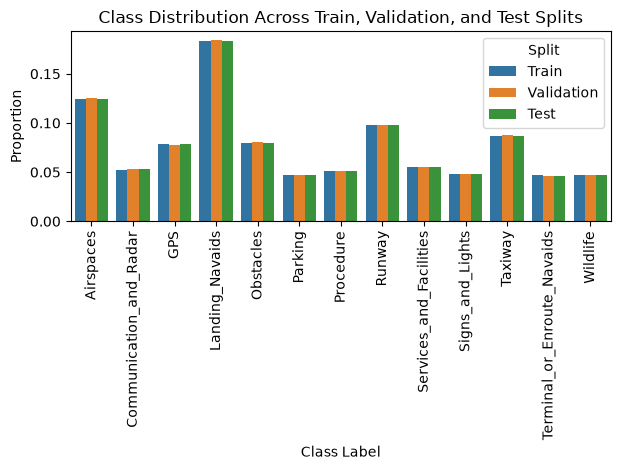

In [10]:
class_distribution_melted = class_distribution.reset_index().melt(id_vars='index', var_name='Split', value_name='Proportion')
sns.barplot(data=class_distribution_melted, x='index', y='Proportion', hue='Split')
plt.title('Class Distribution Across Train, Validation, and Test Splits')
plt.xlabel('Class Label')
plt.ylabel('Proportion')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## Text Length Distribution Analysis

Let's examine the distribution of text lengths (character count and word count) in the training dataset to inform our tokenization strategy. We will look at descriptive statistics and visualize these distributions with histograms.

In [11]:
# Calculate character count distribution
char_counts = train_df['text'].str.len()
print("Character Count Distribution:")
display(char_counts.describe())

# Calculate word count distribution
word_counts = train_df['text'].str.split().str.len()
print("\nWord Count Distribution:")
display(word_counts.describe())

Character Count Distribution:


count    3389.000000
mean      123.416642
std       170.545162
min         7.000000
25%        36.000000
50%        72.000000
75%       141.000000
max      2176.000000
Name: text, dtype: float64


Word Count Distribution:


count    3389.000000
mean       20.425494
std        27.802073
min         2.000000
25%         7.000000
50%        12.000000
75%        24.000000
max       425.000000
Name: text, dtype: float64

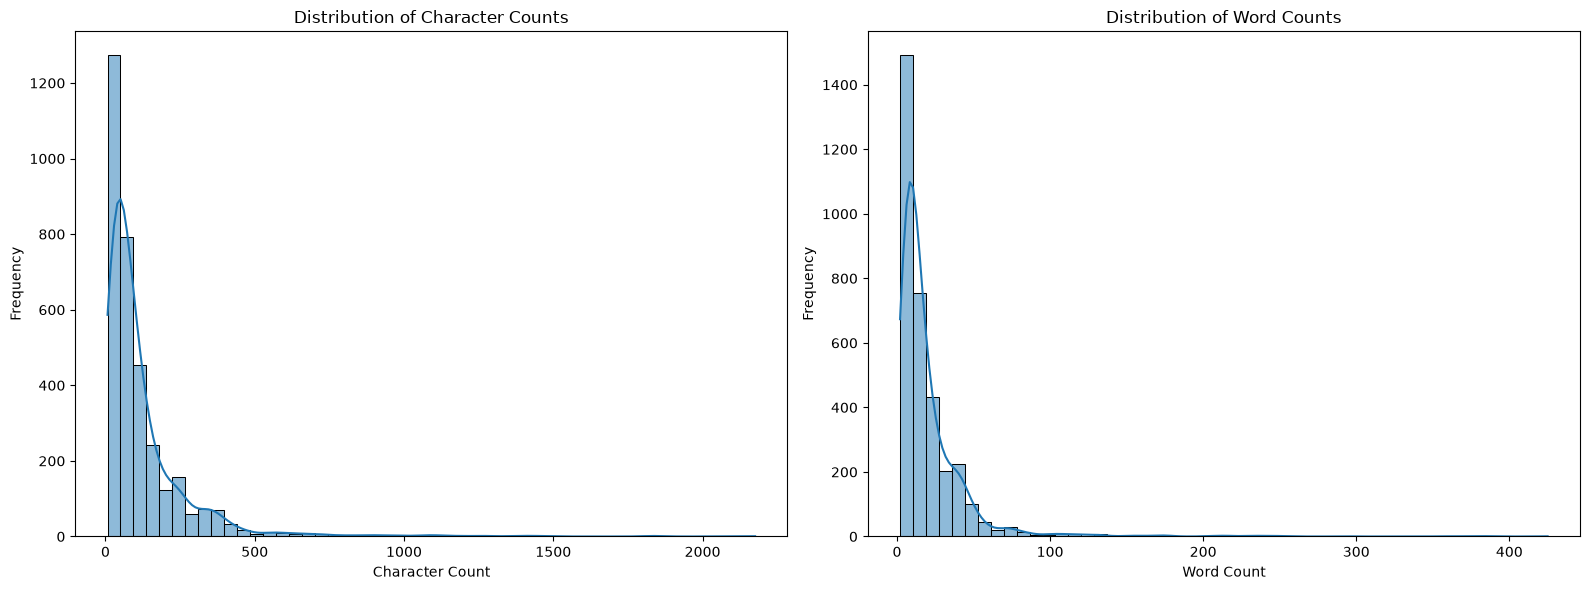

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Histogram for Character Counts
sns.histplot(char_counts, bins=50, kde=True, ax=axes[0])
axes[0].set_title('Distribution of Character Counts')
axes[0].set_xlabel('Character Count')
axes[0].set_ylabel('Frequency')

# Histogram for Word Counts
sns.histplot(word_counts, bins=50, kde=True, ax=axes[1])
axes[1].set_title('Distribution of Word Counts')
axes[1].set_xlabel('Word Count')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

Based on these distributions, you can determine an appropriate `max_length` for tokenization. Typically, you'd choose a value where 95% or 99% of texts fit without truncation. Let's calculate the 95th and 99th percentiles for both character and word counts.

In [13]:
print(f"95th percentile for character count: {char_counts.quantile(0.95):.0f}")
print(f"99th percentile for character count: {char_counts.quantile(0.99):.0f}")

print(f"\n95th percentile for word count: {word_counts.quantile(0.95):.0f}")
print(f"99th percentile for word count: {word_counts.quantile(0.99):.0f}")

95th percentile for character count: 375
99th percentile for character count: 880

95th percentile for word count: 53
99th percentile for word count: 131


## Class-Conditional Text Length Analysis

Now, let's analyze the text length (character and word counts) for each class to see if there are significant differences that might impact classification.

In [14]:
# Add character and word counts to the training DataFrame
train_df['char_count'] = train_df['text'].str.len()
train_df['word_count'] = train_df['text'].str.split().str.len()

# Group by label and calculate mean and max for character and word counts
class_length_stats = train_df.groupby('label').agg(
    mean_char_count=('char_count', 'mean'),
    max_char_count=('char_count', 'max'),
    mean_word_count=('word_count', 'mean'),
    max_word_count=('word_count', 'max')
)

# Map label IDs to label names for better readability
class_length_stats.index = [label_list[i] for i in class_length_stats.index]

print("Class-Conditional Text Length Statistics:")
display(class_length_stats)

Class-Conditional Text Length Statistics:


,mean_char_count,max_char_count,mean_word_count,max_word_count
Airspaces,233.052009,2176,31.813239,370
Communication_and_Radar,116.685393,905,19.505618,129
GPS,150.691729,946,21.691729,165
Landing_Navaids,46.672552,642,9.443018,73
Obstacles,172.450185,2047,27.915129,425
Parking,78.869565,850,13.900621,109
Procedure,183.300578,1822,30.959538,237
Runway,192.798193,2137,35.355422,356
Services_and_Facilities,93.042553,1036,16.090426,138
Signs_and_Lights,64.484663,282,12.736196,60


## Class-Specific Examples for Manual Review

Please carefully read five examples for each class below. Focus on:

1.  **Obvious vocabulary** that distinguishes each class (e.g., does "Wildlife" always contain "BIRD"?).
2.  **Ambiguous examples** where you wouldn't be sure of the class yourself.

After reviewing, please write down 2-3 'hard cases' you notice. These will help us understand the inherent difficulty of the classification task.

In [15]:
for label_id, label_name in enumerate(label_list):
    print(f"\n--- Class: {label_name} (ID: {label_id}) ---")
    class_examples = train_df[train_df['label'] == label_id]['text'].sample(min(5, len(train_df[train_df['label'] == label_id])), random_state=42)
    for i, example in enumerate(class_examples):
        print(f"Example {i+1}: {example}")


--- Class: Airspaces (ID: 0) ---
Example 1: AEROBATICS:
1.FLT AREA   : BOUNDED BY FLW POINTS
               352058N1365922E 352227N1370329E 351954N1370512E
               351912N1370410E 351821N1370528E 351734N1370420E
               351845N1370246E 351920N1370307E 351900N1370125E
               352002N1365938E
               (EAST OF LAKE IRUKA, INUYAMA-SHI IN AICHI)
2.USING ACFT : PTS2
3.FLT TIME   : 0000/SS
4.WX COND    : VMC ONLY
Example 2: EVOLUTIONS MIL ACFT SECT EL NOVICIADO ZONE ...D...WI NXT 
GEO COORD:

332251S  0705249W

332249S  0705008W

332500S  0705006W

332501S  0705249W

INSTRUCTIONS: SANTIAGO  RDR 129.7MHZ

              SANTIAGO  RDR 119.7MHZ

              SANTIAGO INFO 122.4MHZ
Example 3: AUSOTS GROUP B DOMESTIC FLEX TRACKS ACT
TDM TRK XB12 180619060001 

1806190900 1806192200 

ELATI PIPOV EMVAS 15S106E IDOKU HOOLI 24S123E WENER 

27S132E GOMUL DANAL DUCEK CMU BEBAK 

RTS/BEBAK OK AGIVA PARRY Y195 GLENN BN YBBN 

RMK/AUSOTS GROUP B

.

FURTHER INFORMATION ON FLEX

# NOTAM Classifier — Results

Two charts that carry the story of the four runs:

1. **Trajectory** — aggregate val macro-F1 across the five runs, with the TF-IDF baseline as a horizontal reference.
2. **Per-class delta** — how each model family shifts per-class F1 relative to the TF-IDF baseline. The `Procedure` row is the headline.

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path('..').resolve()
OUTPUTS = ROOT / 'outputs'
plt.rcParams['figure.dpi'] = 110

print('OUTPUTS:', OUTPUTS)
print('experiments.csv exists:', (OUTPUTS / 'experiments.csv').exists())

OUTPUTS: /Users/alexandrekouakou/Downloads/Airline_and_Aviation/notam-assistant/outputs
experiments.csv exists: True


In [3]:
df = pd.read_csv(OUTPUTS / 'experiments.csv')
df[['run_id', 'approach', 'val_macro_f1', 'val_procedure_f1']]

,run_id,approach,val_macro_f1,val_procedure_f1
0,1,TF-IDF + LR (balanced),0.910200,0.780000
1,2,DistilBERT fine-tuned,0.942694,0.911392
2,3,DistilBERT fine-tuned (5 epochs),0.946706,0.904762
3,4,LLM zero-shot (anthropic),0.895145,0.657534
4,5,LLM few-shot (anthropic),0.907414,0.714286


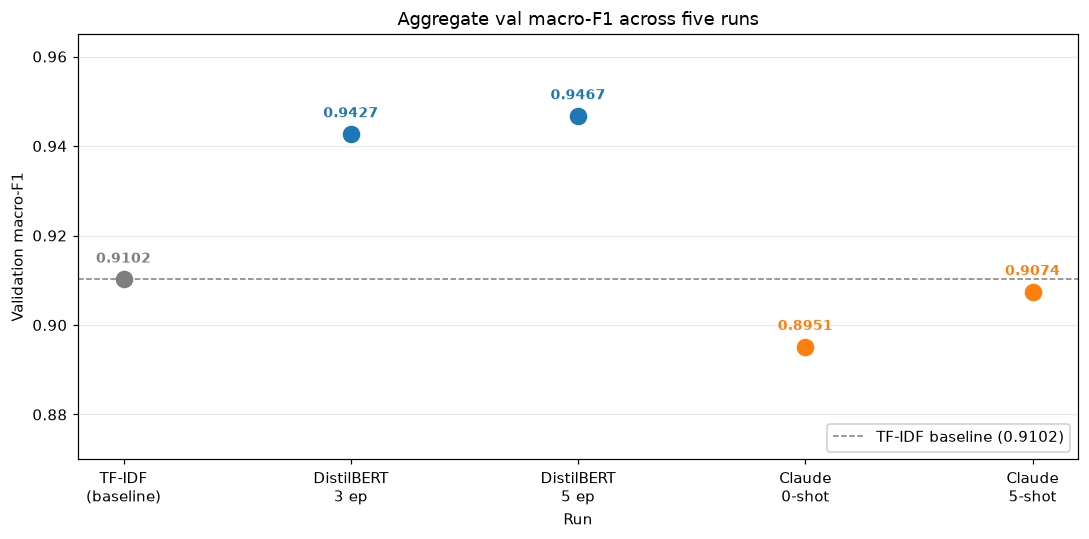

In [4]:
labels = {
    1: 'TF-IDF\n(baseline)',
    2: 'DistilBERT\n3 ep',
    3: 'DistilBERT\n5 ep',
    4: 'Claude\n0-shot',
    5: 'Claude\n5-shot',
}
family_colors = {1: 'tab:gray', 2: 'tab:blue', 3: 'tab:blue',
                 4: 'tab:orange', 5: 'tab:orange'}

baseline_f1 = df.loc[df['run_id'] == 1, 'val_macro_f1'].iloc[0]

fig, ax = plt.subplots(figsize=(10, 5))
ax.axhline(baseline_f1, color='tab:gray', linestyle='--', linewidth=1,
           label=f'TF-IDF baseline ({baseline_f1:.4f})')

for _, row in df.iterrows():
    rid = int(row['run_id'])
    y = row['val_macro_f1']
    ax.scatter(rid, y, s=110, color=family_colors[rid], zorder=3)
    ax.annotate(f'{y:.4f}', (rid, y), textcoords='offset points',
                xytext=(0, 11), ha='center', fontsize=9,
                color=family_colors[rid], fontweight='bold')

ax.set_xticks(df['run_id'].values)
ax.set_xticklabels([labels[i] for i in df['run_id'].values])
ax.set_xlabel('Run')
ax.set_ylabel('Validation macro-F1')
ax.set_title('Aggregate val macro-F1 across five runs')
ax.set_ylim(0.87, 0.965)
ax.grid(axis='y', alpha=0.3)
ax.legend(loc='lower right', framealpha=0.95)

plt.tight_layout()
fig.savefig(OUTPUTS / 'results_trajectory.png', dpi=150,
            bbox_inches='tight', facecolor='white')
plt.show()

**Reading the trajectory.** DistilBERT (blue) clears the TF-IDF baseline (+3.2 points at 3 epochs, +3.6 at 5) and the two DistilBERT runs are within noise of each other — convergence by epoch 4. Both Claude variants (orange) land *below* the baseline (0.8951 and 0.9074 vs 0.9102). Aggregate alone says "fine-tuning beats prompting"; the per-class chart says *why*.

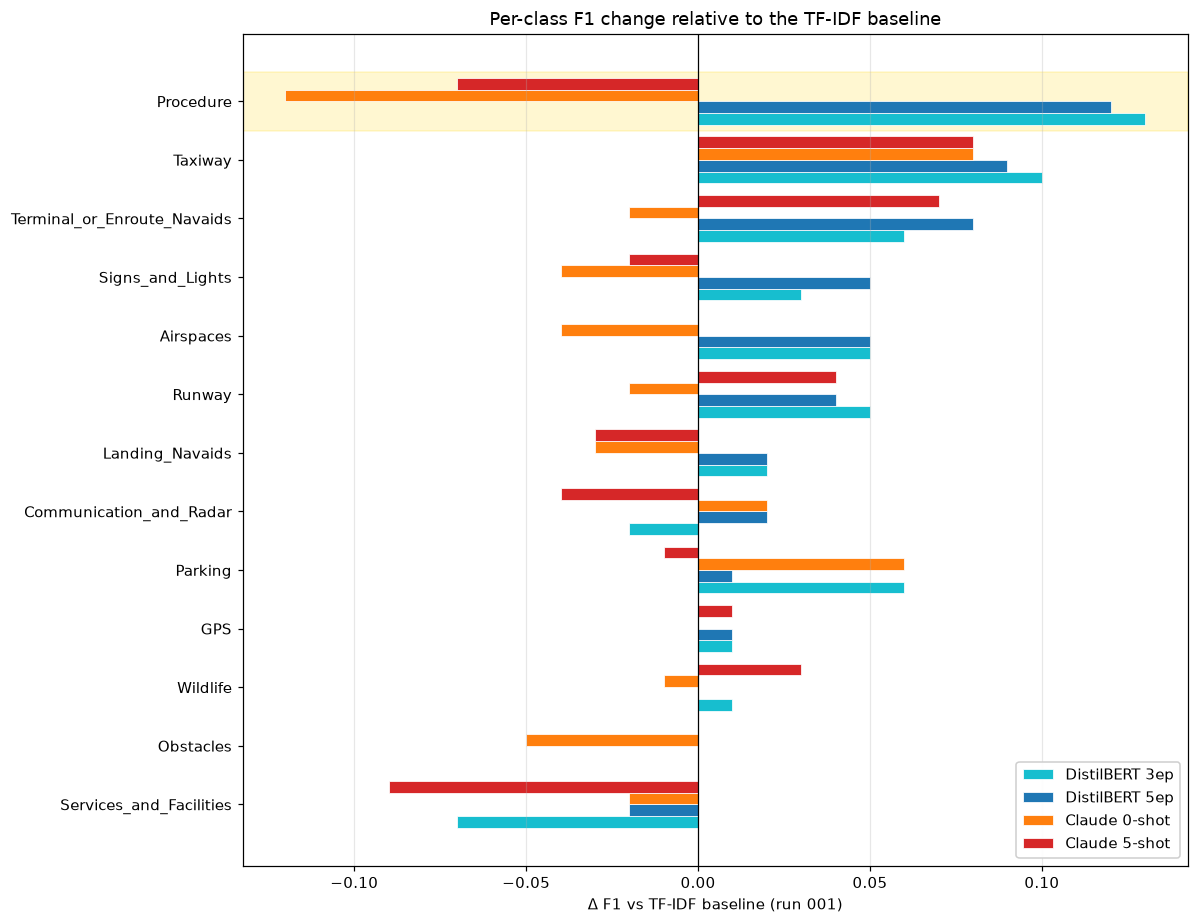

In [3]:
tfidf = {
    'Airspaces': 0.92, 'Communication_and_Radar': 0.87, 'GPS': 0.99,
    'Landing_Navaids': 0.98, 'Obstacles': 0.99, 'Parking': 0.88,
    'Procedure': 0.78, 'Runway': 0.90, 'Services_and_Facilities': 0.89,
    'Signs_and_Lights': 0.90, 'Taxiway': 0.88,
    'Terminal_or_Enroute_Navaids': 0.89, 'Wildlife': 0.96,
}
distilbert_3ep = {
    'Airspaces': 0.97, 'Communication_and_Radar': 0.85, 'GPS': 1.00,
    'Landing_Navaids': 1.00, 'Obstacles': 0.99, 'Parking': 0.94,
    'Procedure': 0.91, 'Runway': 0.95, 'Services_and_Facilities': 0.82,
    'Signs_and_Lights': 0.93, 'Taxiway': 0.98,
    'Terminal_or_Enroute_Navaids': 0.95, 'Wildlife': 0.97,
}
distilbert_5ep = {
    'Airspaces': 0.97, 'Communication_and_Radar': 0.89, 'GPS': 1.00,
    'Landing_Navaids': 1.00, 'Obstacles': 0.99, 'Parking': 0.89,
    'Procedure': 0.90, 'Runway': 0.94, 'Services_and_Facilities': 0.87,
    'Signs_and_Lights': 0.95, 'Taxiway': 0.97,
    'Terminal_or_Enroute_Navaids': 0.97, 'Wildlife': 0.96,
}
claude_0shot = {
    'Airspaces': 0.88, 'Communication_and_Radar': 0.89, 'GPS': 0.99,
    'Landing_Navaids': 0.95, 'Obstacles': 0.94, 'Parking': 0.94,
    'Procedure': 0.66, 'Runway': 0.88, 'Services_and_Facilities': 0.87,
    'Signs_and_Lights': 0.86, 'Taxiway': 0.96,
    'Terminal_or_Enroute_Navaids': 0.87, 'Wildlife': 0.95,
}
claude_5shot = {
    'Airspaces': 0.92, 'Communication_and_Radar': 0.83, 'GPS': 1.00,
    'Landing_Navaids': 0.95, 'Obstacles': 0.99, 'Parking': 0.87,
    'Procedure': 0.71, 'Runway': 0.94, 'Services_and_Facilities': 0.80,
    'Signs_and_Lights': 0.88, 'Taxiway': 0.96,
    'Terminal_or_Enroute_Navaids': 0.96, 'Wildlife': 0.99,
}

# Sort classes by DistilBERT 5ep delta, ascending — biggest gain at the top
order = sorted(tfidf.keys(),
               key=lambda c: distilbert_5ep[c] - tfidf[c])

models = [
    ('DistilBERT 3ep', distilbert_3ep, 'tab:cyan'),
    ('DistilBERT 5ep', distilbert_5ep, 'tab:blue'),
    ('Claude 0-shot',  claude_0shot,  'tab:orange'),
    ('Claude 5-shot',  claude_5shot,  'tab:red'),
]

fig, ax = plt.subplots(figsize=(11, 8.5))
y_pos = np.arange(len(order))
bar_height = 0.20
# Center the four bars around each tick
offsets = np.linspace(-1.5, 1.5, len(models)) * bar_height

# Highlight the Procedure row
proc_idx = order.index('Procedure')
ax.axhspan(proc_idx - 0.5, proc_idx + 0.5, color='gold', alpha=0.18, zorder=0)

for i, (name, data, color) in enumerate(models):
    deltas = [data[c] - tfidf[c] for c in order]
    ax.barh(y_pos + offsets[i], deltas, height=bar_height,
            color=color, label=name, edgecolor='white', linewidth=0.5)

ax.axvline(0, color='black', linewidth=0.8)
ax.set_yticks(y_pos)
ax.set_yticklabels(order)
ax.set_xlabel('Δ F1 vs TF-IDF baseline (run 001)')
ax.set_title('Per-class F1 change relative to the TF-IDF baseline')
ax.grid(axis='x', alpha=0.3)
ax.legend(loc='lower right', framealpha=0.95)

plt.tight_layout()
fig.savefig(OUTPUTS / 'results_per_class_delta.png', dpi=150,
            bbox_inches='tight', facecolor='white')
plt.show()

**Reading the per-class delta.** Most classes cluster near zero. The signal is the highlighted `Procedure` row: DistilBERT lifts it ~12 points, both Claude variants push it *below* the TF-IDF baseline. Two model families, two opposite failures on the same class — the finding the project exists to demonstrate.

**Summary.** Aggregate: fine-tuning DistilBERT beats the baseline (+3.6) and the zero-shot LLM (+4.2). Per-class: the entire gap is `Procedure`, where domain-specific supervision recovers ~12 F1 points that neither vocabulary nor zero-shot priors can supply.